# Practical 1 – Basic Machine Learning Workflow

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score, 
    f1_score, 
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('gdm_synthetic_data.csv')
df.head()

,patient_id,age,pre_pregnancy_bmi,ethnicity,family_history_dm,previous_gdm,pcos,previous_macrosomia,booking_gestational_age,early_rbs_mgdl,early_ppbs_mgdl,early_hba1c_percent,early_ogtt_performed,early_ogtt_fasting_mgdl,early_ogtt_1h_mgdl,early_ogtt_2h_mgdl,gdm_outcome
0,P0001,30.5,25.4,Caucasian,0,0,0,0,10.6,117.5,122.5,5.26,0,NaN,NaN,NaN,0
1,P0002,32.8,24.3,Asian,0,0,0,0,8.5,101.0,144.9,5.27,0,NaN,NaN,NaN,1
2,P0003,27.9,19.8,Caucasian,0,1,0,0,15.6,127.4,147.5,6.10,0,NaN,NaN,NaN,1
3,P0004,25.3,19.5,Caucasian,1,0,1,0,10.3,126.5,163.7,5.47,0,NaN,NaN,NaN,1
4,P0005,22.5,19.2,Caucasian,0,0,1,0,11.9,108.4,156.7,5.39,0,NaN,NaN,NaN,0


In [3]:
df.describe(include='all')

,patient_id,age,pre_pregnancy_bmi,ethnicity,family_history_dm,previous_gdm,pcos,previous_macrosomia,booking_gestational_age,early_rbs_mgdl,early_ppbs_mgdl,early_hba1c_percent,early_ogtt_performed,early_ogtt_fasting_mgdl,early_ogtt_1h_mgdl,early_ogtt_2h_mgdl,gdm_outcome
count,10000,10000.000000,10000.00000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,2952.000000,2952.000000,2952.000000,10000.000000
unique,10000,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,P0001,NaN,NaN,Caucasian,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,3964,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,28.034020,24.67742,NaN,0.251700,0.113200,0.152900,0.097900,10.037310,109.09510,142.539400,5.723652,0.295200,98.467785,181.380589,156.318902,0.650600
std,NaN,4.858715,4.05129,NaN,0.434011,0.316853,0.359909,0.297194,1.968022,18.84861,24.155854,0.583096,0.456155,11.528990,31.936666,26.037690,0.476804
min,NaN,18.000000,16.00000,NaN,0.000000,0.000000,0.000000,0.000000,6.000000,70.00000,90.000000,4.000000,0.000000,70.000000,100.000000,90.000000,0.000000
25%,NaN,24.675000,21.90000,NaN,0.000000,0.000000,0.000000,0.000000,8.600000,96.00000,125.700000,5.320000,0.000000,90.300000,158.800000,138.800000,0.000000
50%,NaN,28.000000,24.60000,NaN,0.000000,0.000000,0.000000,0.000000,10.000000,108.50000,142.200000,5.700000,0.000000,97.800000,181.100000,156.250000,1.000000
75%,NaN,31.400000,27.40000,NaN,1.000000,0.000000,0.000000,0.000000,11.400000,121.70000,158.600000,6.100000,1.000000,106.000000,203.825000,173.925000,1.000000


In [4]:
df.shape

(10000, 17)

In [5]:
df.dtypes

patient_id                  object
age                        float64
pre_pregnancy_bmi          float64
ethnicity                   object
family_history_dm            int64
previous_gdm                 int64
pcos                         int64
previous_macrosomia          int64
booking_gestational_age    float64
early_rbs_mgdl             float64
early_ppbs_mgdl            float64
early_hba1c_percent        float64
early_ogtt_performed         int64
early_ogtt_fasting_mgdl    float64
early_ogtt_1h_mgdl         float64
early_ogtt_2h_mgdl         float64
gdm_outcome                  int64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               10000 non-null  object 
 1   age                      10000 non-null  float64
 2   pre_pregnancy_bmi        10000 non-null  float64
 3   ethnicity                10000 non-null  object 
 4   family_history_dm        10000 non-null  int64  
 5   previous_gdm             10000 non-null  int64  
 6   pcos                     10000 non-null  int64  
 7   previous_macrosomia      10000 non-null  int64  
 8   booking_gestational_age  10000 non-null  float64
 9   early_rbs_mgdl           10000 non-null  float64
 10  early_ppbs_mgdl          10000 non-null  float64
 11  early_hba1c_percent      10000 non-null  float64
 12  early_ogtt_performed     10000 non-null  int64  
 13  early_ogtt_fasting_mgdl  2952 non-null   float64
 14  early_ogtt_1h_mgdl     

In [7]:
df.isnull().sum()

patient_id                    0
age                           0
pre_pregnancy_bmi             0
ethnicity                     0
family_history_dm             0
previous_gdm                  0
pcos                          0
previous_macrosomia           0
booking_gestational_age       0
early_rbs_mgdl                0
early_ppbs_mgdl               0
early_hba1c_percent           0
early_ogtt_performed          0
early_ogtt_fasting_mgdl    7048
early_ogtt_1h_mgdl         7048
early_ogtt_2h_mgdl         7048
gdm_outcome                   0
dtype: int64

In [8]:
df['early_ogtt_performed'].value_counts()

early_ogtt_performed
0    7048
1    2952
Name: count, dtype: int64

In [9]:
pd.crosstab(
    df["early_ogtt_performed"],
    df["early_ogtt_fasting_mgdl"].isna()
)

early_ogtt_fasting_mgdl,False,True
early_ogtt_performed,,
0,0,7048
1,2952,0


7,048 patients did not have an OGTT performed, so their OGTT measurements are missing.

2,952 patients had an OGTT performed, and all of them have their OGTT measurements.

**The OGTT values aren't missing because of an error. They are missing because the test wasn't performed.**

In [10]:
df.drop(columns=['patient_id'], inplace=True)
df.head()

,age,pre_pregnancy_bmi,ethnicity,family_history_dm,previous_gdm,pcos,previous_macrosomia,booking_gestational_age,early_rbs_mgdl,early_ppbs_mgdl,early_hba1c_percent,early_ogtt_performed,early_ogtt_fasting_mgdl,early_ogtt_1h_mgdl,early_ogtt_2h_mgdl,gdm_outcome
0,30.5,25.4,Caucasian,0,0,0,0,10.6,117.5,122.5,5.26,0,NaN,NaN,NaN,0
1,32.8,24.3,Asian,0,0,0,0,8.5,101.0,144.9,5.27,0,NaN,NaN,NaN,1
2,27.9,19.8,Caucasian,0,1,0,0,15.6,127.4,147.5,6.10,0,NaN,NaN,NaN,1
3,25.3,19.5,Caucasian,1,0,1,0,10.3,126.5,163.7,5.47,0,NaN,NaN,NaN,1
4,22.5,19.2,Caucasian,0,0,1,0,11.9,108.4,156.7,5.39,0,NaN,NaN,NaN,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
X=df.drop(columns=['gdm_outcome'])
y=df['gdm_outcome']

In [13]:
print(X.shape,y.shape)

(10000, 15) (10000,)


In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [15]:
categorical_features=['ethnicity']
numerical_features=[
    "age",
    "pre_pregnancy_bmi",
    "family_history_dm",
    "previous_gdm",
    "pcos",
    "previous_macrosomia",
    "booking_gestational_age",
    "early_rbs_mgdl",
    "early_ppbs_mgdl",
    "early_hba1c_percent",
    "early_ogtt_performed",
    "early_ogtt_fasting_mgdl",
    "early_ogtt_1h_mgdl",
    "early_ogtt_2h_mgdl"
]

In [16]:
numerical_transformer=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy='median')),
    ("scaler",StandardScaler())
])

In [17]:
categorical_transformer=Pipeline(steps=[
    ("encoder",OneHotEncoder(handle_unknown='ignore')) #prevents the model from crashing
])

In [18]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",numerical_transformer,numerical_features,),
        ("cat",categorical_transformer,categorical_features)
    ]
)

In [19]:
model=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("classifier",LogisticRegression(max_iter=1000))
])

In [20]:
model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [21]:
y_pred=model.predict(X_test)

In [22]:
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

Predicted: [1 1 1 0 1 1 1 0 0 1]
Actual:    [0 1 1 1 0 1 1 0 0 1]


In [23]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

Accuracy : 72.85%
Precision: 76.14%
Recall   : 84.86%
F1 Score : 80.26%


In [24]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[ 353  346]
 [ 197 1104]]


[[TN FP]

 [FN TP]]

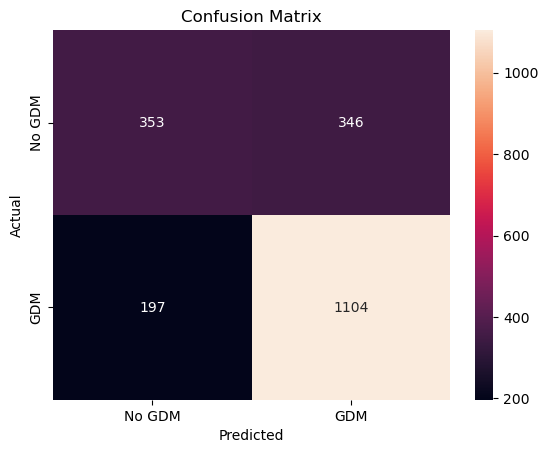

In [25]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=["No GDM","GDM"],
    yticklabels=["No GDM","GDM"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.64      0.51      0.57       699
           1       0.76      0.85      0.80      1301

    accuracy                           0.73      2000
   macro avg       0.70      0.68      0.68      2000
weighted avg       0.72      0.73      0.72      2000



# Observations

- The Logistic Regression model achieved an accuracy of 72.85% on the test dataset. 
- The model performed better in **identifying GDM cases than non-GDM cases** with a recall of
    - 85% for the GDM class 
    - and 51% for the No-GDM class. 
- The confusion matrix showed 1,104 true positive and 353 true negative predictions, while 346 false positives and 197 false negatives were observed. 
- The results indicate that the model is more effective at detecting GDM cases but has a tendency to classify some non-GDM cases as GDM.